In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [8]:
df = pd.read_csv('sales_data_sample.csv', encoding='latin1')
x= df.select_dtypes(include='number')              

In [12]:
x_scaled = StandardScaler().fit_transform(x)

In [13]:
WSS=[]

for i in range(1,11):
    km=KMeans(n_clusters=i, random_state=42)
    km.fit(x_scaled)
    WSS.append(km.inertia_)

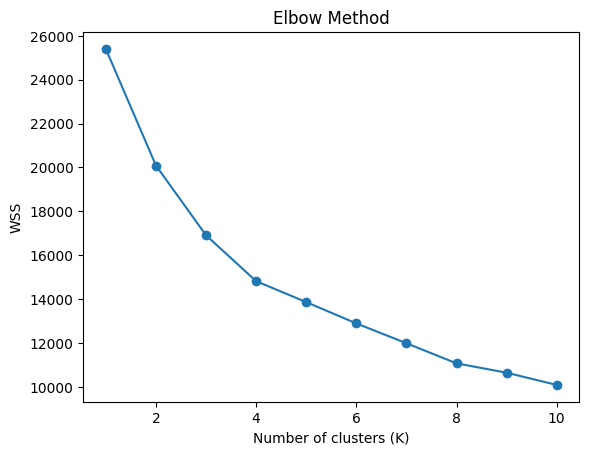

In [32]:
plt.plot(range(1, 11), WSS, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters (K)')
plt.ylabel('WSS')
plt.show()

In [33]:
k=4
df['KMeans']=KMeans(n_clusters=k, random_state=42).fit_predict(x_scaled)

df[['SALES','KMeans']].head()

,SALES,KMeans
0,2871.00,2
1,2765.90,2
2,3884.34,2
3,3746.70,1
4,5205.27,1


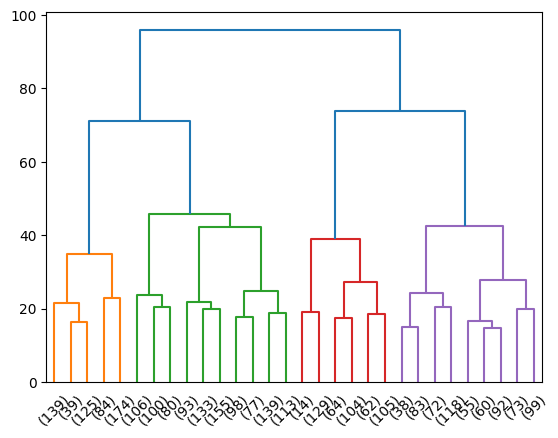

In [34]:
linked=linkage(x_scaled,method='ward')
dendrogram(linked,truncate_mode='lastp', p=30)
plt.show()

In [35]:
df['Hier']=fcluster(linked,k,criterion='maxclust')

In [36]:
print(df[['SALES','KMeans', 'Hier']])

        SALES  KMeans  Hier
0     2871.00       2     4
1     2765.90       2     4
2     3884.34       2     2
3     3746.70       1     1
4     5205.27       1     1
...       ...     ...   ...
2818  2244.40       3     2
2819  3978.51       0     3
2820  5417.57       0     3
2821  2116.16       0     3
2822  3079.44       0     3

[2823 rows x 3 columns]
